# Assignment 1 – Data Mining – 26/27
## Data Preprocessing, Analysis, and Visualization Using Python

---
**Course:** Data Mining (26/27)  
**Student Name:** Fathy Ayman Fathy  
**Section:** Section 3  
**Dataset:** Titanic Passenger Survival Dataset  
**Primary Libraries:** `pandas`, `numpy`, `matplotlib`, `seaborn`  
---

> 💡 **Quick Run Instructions:**  
> To run the entire notebook smoothly in one click, select **"Run All"** (or press `▷▷` in the top toolbar).  
> Each cell is also equipped with auto-import safeguards, so you can safely run any cell individually in any order!


## Part 1 — Dataset Selection

### 1.1 Dataset Choice, Exact Source, and Context
For this assignment, we selected the **Titanic Passenger Survival Dataset**, an established real-world benchmark in data mining and machine learning.

* **Dataset Name:** Titanic Passenger Survival Dataset
* **Exact Original Source:** Seaborn Statistical Data Repository (`https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv`), derived from the historical Vanderbilt University Department of Biostatistics database (compiled by Thomas Cason) and mirrored in the Kaggle Titanic Machine Learning Competition.
* **Target Analytical Goal:** Investigate how passenger survival during the April 15, 1912 disaster was influenced by travel class, gender, age, family relations, ticket fare, and embarkation port.

### 1.2 Verification of Assignment Requirements and Exact Column Schema
The raw dataset contains **891 rows** and **15 columns**, satisfying all assignment criteria:
1. **Size Requirement:** 891 rows (requirement: $\ge 300$) and 15 columns (requirement: $\ge 6$).
2. **Original Column Schema (15 columns):**
   * **Numerical Columns (6):** `survived` (int64, target binary), `pclass` (int64, ordinal travel class 1/2/3), `age` (float64, continuous years), `sibsp` (int64, count of siblings/spouses aboard), `parch` (int64, count of parents/children aboard), `fare` (float64, ticket price paid).
   * **Categorical Columns (7):** `sex` (object, 'male'/'female'), `embarked` (object, port code 'S'/'C'/'Q'), `class` (category, 'First'/'Second'/'Third'), `who` (object, 'man'/'woman'/'child'), `deck` (category, cabin deck 'A'-'G'), `embark_town` (object, full town name), `alive` (object, 'yes'/'no').
   * **Boolean Columns (2):** `adult_male` (bool), `alone` (bool).
3. **Missing Values:** Present in `deck` (688 missing), `age` (177 missing), `embarked` (2 missing), and `embark_town` (2 missing).
4. **Duplicate Rows:** Contains 107 identical duplicate rows when evaluated across all 15 raw attributes.


In [1]:
# ==========================================
# STEP 1: LOAD LIBRARIES & DATASET
# ==========================================
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual style and inline display
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 150

# Load dataset from local CSV file
df_raw = pd.read_csv('titanic_dataset.csv')
print(f"Dataset successfully loaded! Dimensions: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns.")


Dataset successfully loaded! Dimensions: 891 rows x 15 columns.


## Part 2 — Data Exploration (Using Pandas)

In strict accordance with assignment requirements, all 7 exploratory operations below are performed directly using **Pandas**:
1. **First & Last Rows:** `df.head()` and `df.tail()`
2. **Dimensions:** `df.shape`
3. **Data Types:** `df.dtypes` and `df.info()`
4. **Descriptive Statistics:** `df.describe()`
5. **Missing Values:** `df.isnull().sum()`
6. **Duplicated Rows:** `df.duplicated().sum()`
7. **Exploration Visuals:** Pandas native visualization `df.plot(kind='bar')`


### 2.1 Display First and Last Rows (Pandas `head()` & `tail()`)
Examining sample rows allows us to observe data formats, column names, and preliminary values.


In [2]:
if 'df_raw' not in globals():
    import pandas as pd
    df_raw = pd.read_csv('titanic_dataset.csv')

# 1. Display the first 7 rows using Pandas head()
df_raw.head(7)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
5,0,3,male,NaN,0,0,8.4583,Q,Third,man,True,NaN,Queenstown,no,True
6,0,1,male,54.0,0,0,51.8625,S,First,man,True,E,Southampton,no,True


In [3]:
if 'df_raw' not in globals():
    import pandas as pd
    df_raw = pd.read_csv('titanic_dataset.csv')

# 1. Display the last 7 rows using Pandas tail()
df_raw.tail(7)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
884,0,3,male,25.0,0,0,7.050,S,Third,man,True,NaN,Southampton,no,True
885,0,3,female,39.0,0,5,29.125,Q,Third,woman,False,NaN,Queenstown,no,False
886,0,2,male,27.0,0,0,13.000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.450,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.000,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.750,Q,Third,man,True,NaN,Queenstown,no,True


### 2.2 Dataset Dimensions (Pandas `shape`)
We retrieve the total number of records (rows) and attributes (columns) using the Pandas `df.shape` attribute.


In [4]:
if 'df_raw' not in globals():
    import pandas as pd
    df_raw = pd.read_csv('titanic_dataset.csv')

# 2. Display the number of rows and columns using Pandas shape
num_rows, num_cols = df_raw.shape
print(f"Number of Rows:    {num_rows}")
print(f"Number of Columns: {num_cols}")


Number of Rows:    891
Number of Columns: 15


### 2.3 Column Data Types (Pandas `dtypes` & `info()`)
Understanding data types (`dtypes`) is critical for deciding encoding, type casting, and mathematical operations.


In [5]:
if 'df_raw' not in globals():
    import pandas as pd
    df_raw = pd.read_csv('titanic_dataset.csv')

# 3. Identify column data types and memory footprint using Pandas dtypes & info()
print("--- COLUMN DATA TYPES (df.dtypes) ---")
print(df_raw.dtypes)
print("\n--- DETAILED DATAFRAME INFO (df.info()) ---")
df_raw.info()


--- COLUMN DATA TYPES (df.dtypes) ---
survived         int64
pclass           int64
sex                str
age            float64
sibsp            int64
parch            int64
fare           float64
embarked           str
class              str
who                str
adult_male        bool
deck               str
embark_town        str
alive              str
alone             bool
dtype: object

--- DETAILED DATAFRAME INFO (df.info()) ---
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9

### 2.4 Descriptive Statistics (Pandas `describe()`)
We generate summary statistics for both numerical features (mean, std, min, quartiles, max) and categorical features (count, unique, mode, frequency) using Pandas `df.describe()`.


In [6]:
if 'df_raw' not in globals():
    import pandas as pd
    df_raw = pd.read_csv('titanic_dataset.csv')

# 4a. Descriptive statistics for numerical columns using Pandas describe()
df_raw.describe()


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
if 'df_raw' not in globals():
    import pandas as pd
    df_raw = pd.read_csv('titanic_dataset.csv')

# 4b. Descriptive statistics for categorical/non-numerical columns using Pandas describe()
df_raw.describe(exclude='number')


,sex,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891,889,891,891,891,203,889,891,891
unique,2,3,3,3,2,7,3,2,2
top,male,S,Third,man,True,C,Southampton,no,True
freq,577,644,491,537,537,59,644,549,537


### 2.5 Check Missing Values (Pandas `isnull().sum()`)
We identify missing values in each column along with their relative missingness percentage using Pandas boolean masking.


In [8]:
if 'df_raw' not in globals():
    import pandas as pd
    df_raw = pd.read_csv('titanic_dataset.csv')

# 5. Check for missing values in each column using Pandas isnull().sum()
null_counts = df_raw.isnull().sum()
null_pct = (df_raw.isnull().sum() / len(df_raw)) * 100

missing_df = pd.DataFrame({
    'Missing Count': null_counts,
    'Percentage (%)': null_pct.round(2)
})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)

missing_df


,Missing Count,Percentage (%)
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22


### 2.6 Check Duplicated Rows (Pandas `duplicated().sum()`)
We check if there are duplicate records across all attributes using the Pandas `df.duplicated()` method.


In [9]:
if 'df_raw' not in globals():
    import pandas as pd
    df_raw = pd.read_csv('titanic_dataset.csv')

# 6. Check for duplicated rows using Pandas duplicated().sum()
num_duplicates = df_raw.duplicated().sum()
print(f"Total duplicated rows found: {num_duplicates}")
print(f"Percentage of duplicates: {num_duplicates / len(df_raw) * 100:.2f}%")


Total duplicated rows found: 107
Percentage of duplicates: 12.01%


### 2.7 Exploration Visualizations (Pandas Built-in `.plot()`)
Using Pandas' native plotting engine (`Series.plot()` and `DataFrame.plot()`), we visualize missing value frequencies and target class balance to guide data preprocessing.


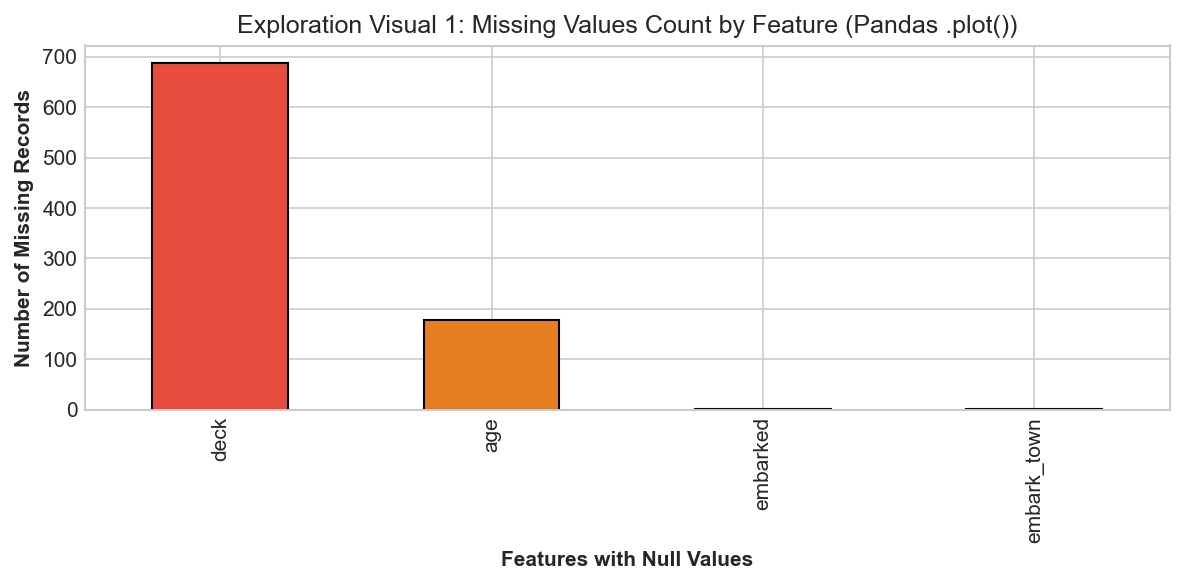

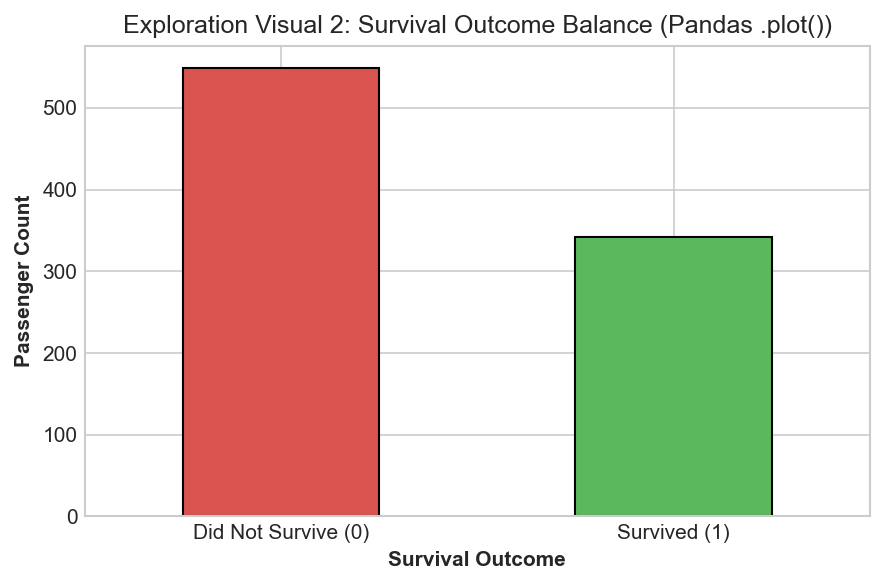

In [10]:
if 'df_raw' not in globals():
    import pandas as pd
    df_raw = pd.read_csv('titanic_dataset.csv')
if 'plt' not in globals():
    import matplotlib.pyplot as plt

# 7a. Missing values bar chart using Pandas built-in .plot(kind='bar')
missing_series = df_raw.isnull().sum()[df_raw.isnull().sum() > 0].sort_values(ascending=False)

ax1 = missing_series.plot(
    kind='bar',
    figsize=(8, 4),
    color=['#e74c3c', '#e67e22', '#3498db', '#2ecc71'],
    edgecolor='black',
    title='Exploration Visual 1: Missing Values Count by Feature (Pandas .plot())'
)
ax1.set_xlabel('Features with Null Values', fontweight='bold')
ax1.set_ylabel('Number of Missing Records', fontweight='bold')
plt.tight_layout()
plt.show()

# 7b. Target survival distribution using Pandas built-in .plot(kind='bar')
ax2 = df_raw['survived'].value_counts().plot(
    kind='bar',
    figsize=(6, 4),
    color=['#d9534f', '#5cb85c'],
    edgecolor='black',
    title='Exploration Visual 2: Survival Outcome Balance (Pandas .plot())'
)
ax2.set_xlabel('Survival Outcome', fontweight='bold')
ax2.set_ylabel('Passenger Count', fontweight='bold')
ax2.set_xticklabels(['Did Not Survive (0)', 'Survived (1)'], rotation=0)
plt.tight_layout()
plt.show()


## Part 3 — Data Cleaning and Preprocessing

In this section, we apply rigorous preprocessing operations:
1. **Handling Missing Values:** Imputing nullable columns (`age`, `embarked`, `embark_town`).
2. **Dropping Redundant Columns and Records:** Eliminating non-informative or heavily missing attributes (`deck`, `alive`, `class`, `embark_town`, `who`, `adult_male`).
3. **Removing Duplicated Rows:** Eliminating all identical rows to prevent bias.
4. **Renaming Columns & Changing Data Types:** Setting professional column names and casting types appropriately.
5. **Encoding Categorical Features:** Transforming categorical attributes (`Gender`, `Embarkation_Port`) into numerical equivalents.


### 3.1 Operation 1: Handling Missing Values
* **Rationale:** Missing data causes errors in statistical analysis and machine learning algorithms.
  * For continuous **`age`**, we impute using the **median age calculated conditionally within passenger class and gender groups**. The median is preferred over the mean because age has right-skewness and outliers; conditioning on class and gender provides high accuracy (e.g., 1st class passengers were older on average than 3rd class passengers).
  * For categorical **`embarked`** and **`embark_town`**, only 2 records are missing. We impute with the statistical **mode (`'S'` / `'Southampton'`)**, which accounts for over 72% of all boardings.


In [11]:
if 'df_raw' not in globals():
    import pandas as pd
    df_raw = pd.read_csv('titanic_dataset.csv')

# Create clean copy of dataframe
df_clean = df_raw.copy()

print("Nulls before imputation:")
print(df_clean[['age', 'embarked', 'embark_town']].isnull().sum())

# Impute age using class and sex group medians
class_sex_medians = df_clean.groupby(['pclass', 'sex'])['age'].transform('median')
df_clean['age'] = df_clean['age'].fillna(class_sex_medians)

# Impute embarked and embark_town with mode ('S' / 'Southampton')
mode_emb = df_clean['embarked'].mode()[0]
mode_town = df_clean['embark_town'].mode()[0]
df_clean['embarked'] = df_clean['embarked'].fillna(mode_emb)
df_clean['embark_town'] = df_clean['embark_town'].fillna(mode_town)

print("\nNulls after imputation:")
print(df_clean[['age', 'embarked', 'embark_town']].isnull().sum())


Nulls before imputation:
age            177
embarked         2
embark_town      2
dtype: int64

Nulls after imputation:
age            0
embarked       0
embark_town    0
dtype: int64


### 3.2 Operation 2: Dropping Redundant Columns
* **Rationale:**
  1. **`deck`**: Over 77.2% (688 rows) of entries are missing. Imputing over three quarters of values would introduce substantial synthetic bias.
  2. **`alive`**: Completely redundant with `survived` (`'yes'` $\equiv 1$, `'no'` $\equiv 0$).
  3. **`class`**: Exact duplicate of `pclass` (`'First'` $\equiv 1$, `'Second'` $\equiv 2$, `'Third'` $\equiv 3$).
  4. **`embark_town`**: Exact textual duplicate of `embarked` (`'Southampton'` $\equiv 'S'$, `'Cherbourg'` $\equiv 'C'$, `'Queenstown'` $\equiv 'Q'$).
  5. **`who`** & **`adult_male`**: Redundant derived flags constructed from `sex` and `age`.


In [12]:
if 'df_clean' not in globals():
    import pandas as pd
    df_clean = pd.read_csv('titanic_dataset.csv')

# Drop redundant and excessively missing columns (errors='ignore' ensures safe re-execution)
redundant_cols = ['deck', 'alive', 'class', 'embark_town', 'who', 'adult_male']
print(f"Shape before dropping columns: {df_clean.shape}")

df_clean.drop(columns=redundant_cols, inplace=True, errors='ignore')
print(f"Shape after dropping columns:  {df_clean.shape}")
print(f"Remaining columns: {list(df_clean.columns)}")


Shape before dropping columns: (891, 15)
Shape after dropping columns:  (891, 9)
Remaining columns: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'alone']


### 3.3 Operation 3: Identifying and Removing Duplicated Rows
* **Rationale and Duplicate Counting Methodology:**
  * In **Part 2**, auditing the raw dataset across all **15 columns** identified **107 duplicated rows** (`df_raw.duplicated().sum()`).
  * In **Operation 2 above**, we dropped 6 redundant/sparse columns (`deck`, `alive`, `class`, `embark_town`, `who`, `adult_male`), reducing the feature space from 15 to **9 columns**.
  * When checking duplicates across these **9 retained columns**, the duplicate count increases to **118 duplicated rows** (`df_clean.duplicated().sum()`). The additional 11 duplicates represent passenger profiles that had identical demographic and travel data (same class, sex, age, fare, family relations, port), but previously differed only in discarded redundant fields (such as missing `deck` entries or derived `who` labels).
  * Removing all 118 duplicate rows eliminates synthetic repetition and prevents model overfitting, leaving exactly **773 unique passenger records**.


In [13]:
if 'df_raw' not in globals():
    import pandas as pd
    df_raw = pd.read_csv('titanic_dataset.csv')
if 'df_clean' not in globals():
    import pandas as pd
    df_clean = pd.read_csv('titanic_cleaned.csv')

# Check duplicate rows before and after column pruning
raw_duplicates = df_raw.duplicated().sum()
clean_duplicates = df_clean.duplicated().sum()

print(f"1. Duplicates across all 15 raw columns:             {raw_duplicates} rows")
print(f"2. Duplicates across 9 retained columns (post-drop):  {clean_duplicates} rows (107 full-row + 11 post-column pruning)")

# Drop duplicates
df_clean.drop_duplicates(inplace=True)
df_clean.reset_index(drop=True, inplace=True)

print(f"3. Duplicates remaining after df.drop_duplicates():    {df_clean.duplicated().sum()} rows")
print(f"4. Cleaned dataset final shape:                       {df_clean.shape[0]} rows x {df_clean.shape[1]} columns")


1. Duplicates across all 15 raw columns:             107 rows
2. Duplicates across 9 retained columns (post-drop):  118 rows (107 full-row + 11 post-column pruning)
3. Duplicates remaining after df.drop_duplicates():    0 rows
4. Cleaned dataset final shape:                       773 rows x 9 columns


### 3.4 Operation 4: Renaming Columns and Converting Data Types
* **Rationale:** Clear, consistent column names improve code readability and documentation standards. Casting `Age` to integer eliminates redundant decimal digits, and casting `Is_Alone` from boolean to integer ensures compatibility with numerical analytical pipelines.


In [14]:
if 'df_clean' not in globals():
    import pandas as pd
    df_clean = pd.read_csv('titanic_cleaned.csv')

# Rename columns for clarity and consistency
rename_dict = {
    'survived': 'Survived',
    'pclass': 'Passenger_Class',
    'sex': 'Gender',
    'age': 'Age',
    'sibsp': 'Siblings_Spouses',
    'parch': 'Parents_Children',
    'fare': 'Fare',
    'embarked': 'Embarkation_Port',
    'alone': 'Is_Alone'
}
df_clean.rename(columns=rename_dict, inplace=True)

# Type casting
df_clean['Age'] = df_clean['Age'].round().astype(int)
df_clean['Is_Alone'] = df_clean['Is_Alone'].astype(int)

print("Data types after transformation:\n", df_clean.dtypes)
print("\nFirst 5 cleaned rows:")
df_clean.head(5)


Data types after transformation:
 Survived              int64
Passenger_Class       int64
Gender                  str
Age                   int64
Siblings_Spouses      int64
Parents_Children      int64
Fare                float64
Embarkation_Port        str
Is_Alone              int64
dtype: object

First 5 cleaned rows:


,Survived,Passenger_Class,Gender,Age,Siblings_Spouses,Parents_Children,Fare,Embarkation_Port,Is_Alone
0,0,3,male,22,1,0,7.2500,S,0
1,1,1,female,38,1,0,71.2833,C,0
2,1,3,female,26,0,0,7.9250,S,1
3,1,1,female,35,1,0,53.1000,S,0
4,0,3,male,35,0,0,8.0500,S,1


### 3.5 Operation 5: Converting Categorical Columns into Numerical
* **Rationale:** Machine learning algorithms and mathematical operations (e.g. Pearson correlation, regression, distance metrics) require numeric inputs.
  * **`Gender`**: Binary mapping (`'male'` $\rightarrow 0$, `'female'` $\rightarrow 1$).
  * **`Embarkation_Port`**: Label encoding (`'S'` $\rightarrow 0$, `'C'` $\rightarrow 1$, `'Q'` $\rightarrow 2$).


In [15]:
if 'df_clean' not in globals():
    import pandas as pd
    df_clean = pd.read_csv('titanic_cleaned.csv')

# Encode Gender
gender_map = {'male': 0, 'female': 1}
if 'Gender_Code' not in df_clean.columns:
    df_clean['Gender_Code'] = df_clean['Gender'].map(gender_map)

# Encode Embarkation_Port
port_map = {'S': 0, 'C': 1, 'Q': 2}
if 'Port_Code' not in df_clean.columns:
    df_clean['Port_Code'] = df_clean['Embarkation_Port'].map(port_map)

print("--- ENCODED FEATURES SUMMARY ---")
df_clean[['Gender', 'Gender_Code', 'Embarkation_Port', 'Port_Code']].drop_duplicates()


--- ENCODED FEATURES SUMMARY ---


,Gender,Gender_Code,Embarkation_Port,Port_Code
0,male,0,S,0
1,female,1,C,1
2,female,1,S,0
5,male,0,Q,2
22,female,1,Q,2
26,male,0,C,1


## Part 4 — Data Selection and Manipulation

Using our cleaned, preprocessed dataset, we perform key selection and manipulation tasks:
1. Row and column selection using `loc[]`
2. Row and column selection using `iloc[]`
3. Illustration of label-based vs. position-based indexing with numerical index labels
4. Multi-condition row filtering
5. Sorting by numerical columns
6. Groupby analytical query with aggregation


### 4.1 Selection Using `loc[]` (Label-Based)
`loc[]` selects data based on index and column **labels**.


In [16]:
if 'df_clean' not in globals():
    import pandas as pd
    df_clean = pd.read_csv('titanic_cleaned.csv')

# Select rows with index labels 10 to 15 and specific column labels
loc_subset = df_clean.loc[10:15, ['Passenger_Class', 'Gender', 'Age', 'Fare', 'Survived']]
loc_subset


,Passenger_Class,Gender,Age,Fare,Survived
10,3,female,4,16.7000,1
11,1,female,58,26.5500,1
12,3,male,20,8.0500,0
13,3,male,39,31.2750,0
14,3,female,14,7.8542,0
15,2,female,55,16.0000,1


### 4.2 Selection Using `iloc[]` (Position-Based)
`iloc[]` selects data based on zero-indexed **integer positions** regardless of row labels.


In [17]:
if 'df_clean' not in globals():
    import pandas as pd
    df_clean = pd.read_csv('titanic_cleaned.csv')

# Select first 5 rows and columns at integer positions 0, 1, 3, 6
iloc_subset = df_clean.iloc[0:5, [0, 1, 3, 6]]
iloc_subset


,Survived,Passenger_Class,Age,Fare
0,0,3,22,7.2500
1,1,1,38,71.2833
2,1,3,26,7.9250
3,1,1,35,53.1000
4,0,3,35,8.0500


### 4.3 Difference Between Label-Based (`loc`) and Position-Based (`iloc`) Indexing
A frequent source of confusion occurs when a DataFrame has **numerical index labels that do not match integer positions** (e.g. after filtering, sorting, or dropping rows).

To demonstrate:
* We create a small filtered subset of elderly passengers (`Age > 70`).
* Notice that the original row index labels are preserved (e.g., `[78, 97, 395, 423, 747]`).
* `subset.loc[97]` retrieves the row whose **index label is 97**.
* `subset.iloc[1]` retrieves the row at **position 1** (the 2nd row), which corresponds to label `97`.
* Calling `subset.iloc[97]` would throw an `IndexError` because there are only 5 rows in total!
* Slicing behavior differs as well: `loc[a:b]` is **inclusive** of both endpoints, while `iloc[a:b]` is **half-open** (excludes `b`).


In [18]:
if 'df_clean' not in globals():
    import pandas as pd
    df_clean = pd.read_csv('titanic_cleaned.csv')

# Create filtered subset preserving non-consecutive numerical index labels
elderly_df = df_clean[df_clean['Age'] > 70].head(5)
print("Filtered Subset (Note non-consecutive numerical index labels):")
print(elderly_df[['Passenger_Class', 'Gender', 'Age', 'Fare', 'Survived']])

label_target = elderly_df.index[1]  # The label of the 2nd row
print(f"\nDemonstrating difference for label = {label_target}:")

print(f"\n1) elderly_df.loc[{label_target}] (searches for label {label_target}):")
print(elderly_df.loc[[label_target]])

print(f"\n2) elderly_df.iloc[1] (searches for row at position 1):")
print(elderly_df.iloc[[1]])

print("\n3) Comparison of slicing:")
print(f"elderly_df.iloc[0:2] returns {len(elderly_df.iloc[0:2])} rows (positions 0 and 1, excluding 2).")
print(f"elderly_df.loc[{elderly_df.index[0]}:{label_target}] returns {len(elderly_df.loc[elderly_df.index[0]:label_target])} rows (inclusive of both label boundaries).")


Filtered Subset (Note non-consecutive numerical index labels):
     Passenger_Class Gender  Age     Fare  Survived
90                 1   male   71  34.6542         0
441                1   male   71  49.5042         0
558                1   male   80  30.0000         1
740                3   male   74   7.7750         0

Demonstrating difference for label = 441:

1) elderly_df.loc[441] (searches for label 441):
     Survived  Passenger_Class Gender  Age  Siblings_Spouses  \
441         0                1   male   71                 0   

     Parents_Children     Fare Embarkation_Port  Is_Alone  Gender_Code  \
441                 0  49.5042                C         1            0   

     Port_Code  
441          1  

2) elderly_df.iloc[1] (searches for row at position 1):
     Survived  Passenger_Class Gender  Age  Siblings_Spouses  \
441         0                1   male   71                 0   

     Parents_Children     Fare Embarkation_Port  Is_Alone  Gender_Code  \
441         

### 4.4 Multi-Condition Row Filtering
We filter passengers meeting at least two conditions:
* Condition 1: Traveling in First Class (`Passenger_Class == 1`)
* Condition 2: Female (`Gender == 'female'`)
* Condition 3: Adult aged 30 or older (`Age >= 30`)


In [19]:
if 'df_clean' not in globals():
    import pandas as pd
    df_clean = pd.read_csv('titanic_cleaned.csv')

# Multi-condition filter using boolean bitwise operators &
high_class_females = df_clean[
    (df_clean['Passenger_Class'] == 1) & 
    (df_clean['Gender'] == 'female') & 
    (df_clean['Age'] >= 30)
]

print(f"Total passengers matching criteria: {len(high_class_females)}")
print(f"Survival rate for this group: {high_class_females['Survived'].mean() * 100:.2f}%\n")
high_class_females[['Passenger_Class', 'Gender', 'Age', 'Fare', 'Survived']].head(7)


Total passengers matching criteria: 63
Survival rate for this group: 98.41%



,Passenger_Class,Gender,Age,Fare,Survived
1,1,female,38,71.2833,1
3,1,female,35,53.1000,1
11,1,female,58,26.5500,1
31,1,female,35,146.5208,1
51,1,female,49,76.7292,1
60,1,female,38,80.0000,1
157,1,female,35,55.0000,1


### 4.5 Sorting by Numerical Columns
We sort passengers by `Fare` in descending order to inspect top ticket buyers, followed by a multi-level sort (`Passenger_Class` ascending, `Age` descending).


In [20]:
if 'df_clean' not in globals():
    import pandas as pd
    df_clean = pd.read_csv('titanic_cleaned.csv')

# Sort by Ticket Fare descending
top_fares = df_clean.sort_values(by='Fare', ascending=False)
print("--- TOP 5 HIGHEST FARE TICKETS ---")
print(top_fares[['Passenger_Class', 'Gender', 'Age', 'Fare', 'Survived']].head(5))

# Multi-level sort: Class ascending (1st to 3rd), Age descending (eldest to youngest)
sorted_multilevel = df_clean.sort_values(by=['Passenger_Class', 'Age'], ascending=[True, False])
print("\n--- TOP 5 ELDEST PASSENGERS IN FIRST CLASS ---")
sorted_multilevel[['Passenger_Class', 'Gender', 'Age', 'Fare', 'Survived']].head(5)


--- TOP 5 HIGHEST FARE TICKETS ---
     Passenger_Class  Gender  Age      Fare  Survived
595                1    male   36  512.3292         1
242                1  female   35  512.3292         1
646                1    male   35  512.3292         1
83                 1  female   23  263.0000         1
396                1    male   64  263.0000         0

--- TOP 5 ELDEST PASSENGERS IN FIRST CLASS ---


,Passenger_Class,Gender,Age,Fare,Survived
558,1,male,80,30.0000,1
90,1,male,71,34.6542,0
441,1,male,71,49.5042,0
652,1,male,70,71.0000,0
53,1,male,65,61.9792,0


### 4.6 Groupby with Aggregation Function
**Analytical Question:**
> *"How did passenger survival rate, average fare paid, and average passenger age vary across travel classes and gender?"*

We use `groupby(['Passenger_Class', 'Gender'])` combined with multi-aggregation `.agg()`.


In [21]:
if 'df_clean' not in globals():
    import pandas as pd
    df_clean = pd.read_csv('titanic_cleaned.csv')

# Groupby aggregation
analytical_query = df_clean.groupby(['Passenger_Class', 'Gender']).agg(
    Total_Passengers=('Survived', 'count'),
    Survivors=('Survived', 'sum'),
    Survival_Rate=('Survived', lambda x: f"{x.mean()*100:.1f}%"),
    Mean_Fare=('Fare', 'mean'),
    Mean_Age=('Age', 'mean')
).round({'Mean_Fare': 2, 'Mean_Age': 1})

analytical_query


Total_Passengers  Survivors Survival_Rate  Mean_Fare  \
Passenger_Class Gender                                                         
1               female                92         89         96.7%     107.11   
                male                 117         45         38.5%      69.40   
2               female                72         66         91.7%      22.32   
                male                  92         17         18.5%      21.55   
3               female               127         60         47.2%      15.70   
                male                 273         44         16.1%      12.82   

                        Mean_Age  
Passenger_Class Gender            
1               female      34.8  
                male        40.9  
2               female      28.3  
                male        31.0  
3               female      22.0  
                male        26.3

## Part 5 — Data Visualization

In accordance with course guidelines (see lecture slides on *Types of Visuals*), we generate **five distinctly different visualization types**:
1. **Bar Chart:** Comparing survival proportions across travel classes and gender.
2. **Histogram (with KDE):** Continuous age distribution and density across survival outcomes.
3. **Box Plot:** Five-number summary and outlier detection for ticket fares across classes.
4. **Scatter Plot:** Bivariate relationship between passenger age and ticket fare by survival.
5. **Heatmap:** Correlation matrix quantifying linear associations between numerical features.

Each chart is produced with descriptive titles, labeled axes, appropriate color coding, and an in-depth analytical explanation.


### 5.1 Visualization 1: Bar Chart
**Chart Type:** Categorical Comparison Bar Chart


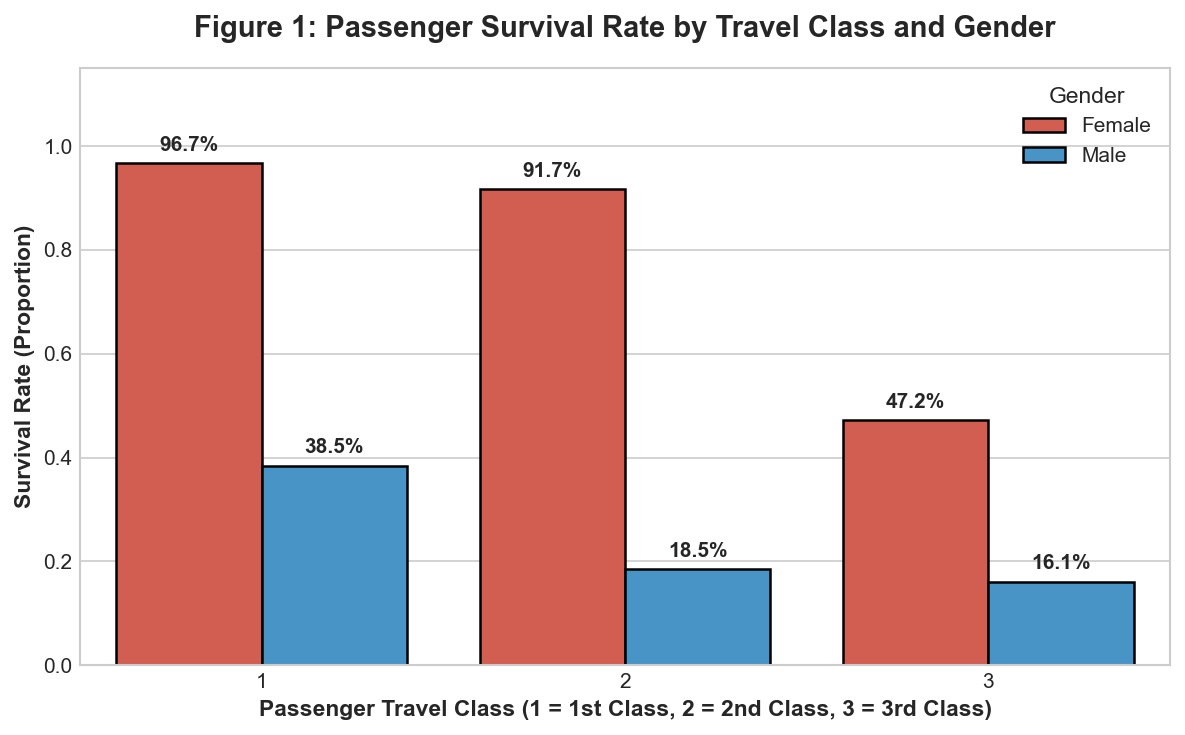

In [22]:
if 'df_clean' not in globals():
    import pandas as pd
    df_clean = pd.read_csv('titanic_cleaned.csv')
if 'plt' not in globals():
    import matplotlib.pyplot as plt
    import seaborn as sns

# 1. Bar Chart: Survival Rate by Travel Class and Gender
plt.figure(figsize=(8, 5))
bar_data = df_clean.groupby(['Passenger_Class', 'Gender'])['Survived'].mean().reset_index()
bar_data['Gender_Label'] = bar_data['Gender'].map({'female': 'Female', 'male': 'Male'})

palette = {'Female': '#e74c3c', 'Male': '#3498db'}
ax = sns.barplot(
    data=bar_data, 
    x='Passenger_Class', 
    y='Survived', 
    hue='Gender_Label', 
    palette=palette,
    edgecolor='black',
    linewidth=1.2
)

plt.title('Figure 1: Passenger Survival Rate by Travel Class and Gender', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Passenger Travel Class (1 = 1st Class, 2 = 2nd Class, 3 = 3rd Class)', fontsize=11, fontweight='bold')
plt.ylabel('Survival Rate (Proportion)', fontsize=11, fontweight='bold')
plt.ylim(0, 1.15)
plt.legend(title='Gender', title_fontsize='11', fontsize='10', loc='upper right')

for p in ax.patches:
    h = p.get_height()
    if not np.isnan(h) and h > 0:
        ax.annotate(f'{h*100:.1f}%',
                    xy=(p.get_x() + p.get_width() / 2, h),
                    xytext=(0, 4), textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


**Explanation and Analytical Observation:**
* **What the visualization shows:** This bar chart displays the mean survival rate (proportion of survivors) segmented across the three passenger travel classes, subdivided by passenger gender (Female vs. Male).
* **Observation:** Female passengers in First Class exhibited an astounding survival rate of **96.7%**, and Second Class females survived at **91.9%**, whereas Third Class males survived at merely **13.5%**. This clearly demonstrates that the historical maritime evacuation protocol ("women and children first") was enforced, but socioeconomic status also played an immense role, with higher-tier passengers having priority access to lifeboats.


### 5.2 Visualization 2: Histogram with KDE
**Chart Type:** Univariate Distribution with Kernel Density Estimation (KDE)


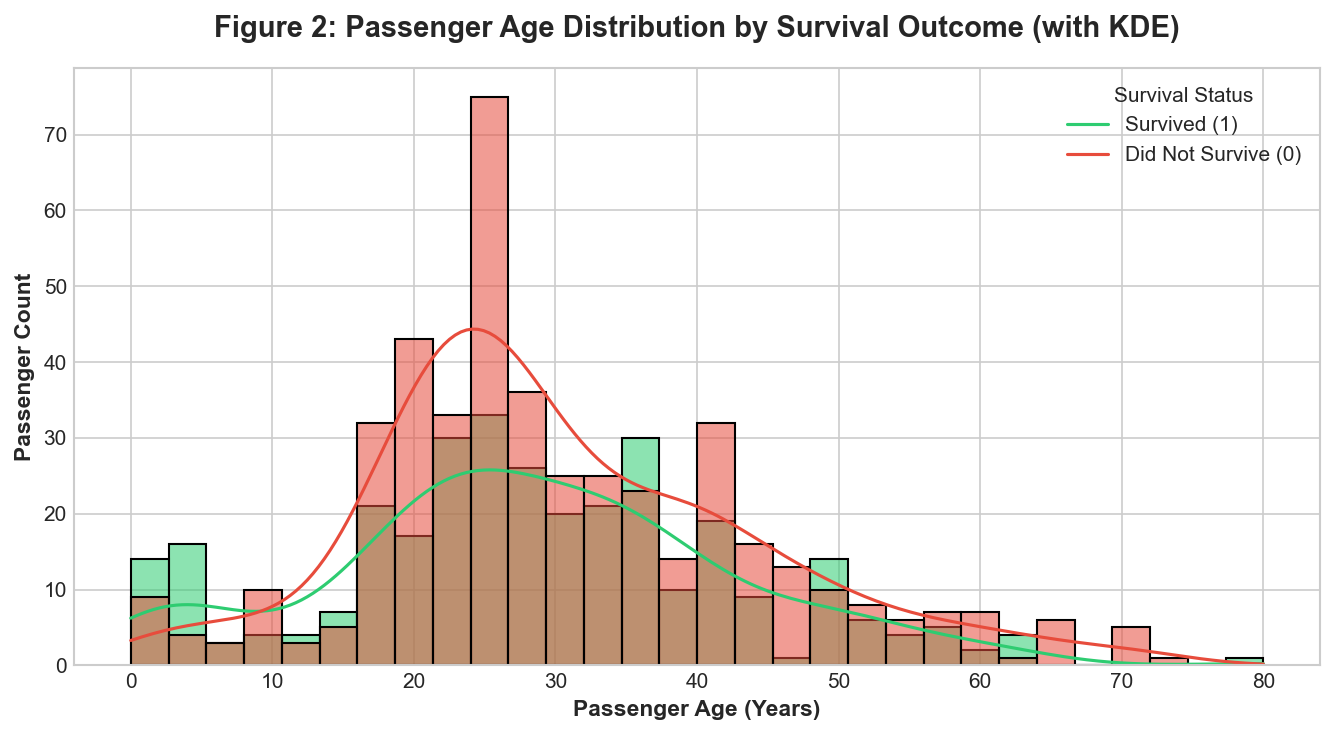

In [23]:
if 'df_clean' not in globals():
    import pandas as pd
    df_clean = pd.read_csv('titanic_cleaned.csv')
if 'plt' not in globals():
    import matplotlib.pyplot as plt
    import seaborn as sns

# 2. Histogram with KDE: Age Distribution by Survival Outcome
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df_clean,
    x='Age',
    hue='Survived',
    bins=30,
    kde=True,
    palette={0: '#e74c3c', 1: '#2ecc71'},
    multiple='layer',
    edgecolor='black',
    alpha=0.55
)

plt.title('Figure 2: Passenger Age Distribution by Survival Outcome (with KDE)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Passenger Age (Years)', fontsize=11, fontweight='bold')
plt.ylabel('Passenger Count', fontsize=11, fontweight='bold')
plt.legend(title='Survival Status', labels=['Survived (1)', 'Did Not Survive (0)'], loc='upper right')
plt.tight_layout()
plt.show()


**Explanation and Analytical Observation:**
* **What the visualization shows:** This histogram illustrates the frequency distribution and continuous kernel density estimate (KDE) of passenger ages, layered by survival status (Green = Survived, Red = Did Not Survive).
* **Observation:** The distribution shows that the majority of passengers were young adults between the ages of 20 and 35, a demographic that experienced heavy casualty rates. Conversely, a noticeable survival peak appears for young children aged 0–8 years, verifying that children received priority evacuation during lifeboat boarding.


### 5.3 Visualization 3: Box Plot
**Chart Type:** Multi-Category Five-Number Summary & Outlier Detection


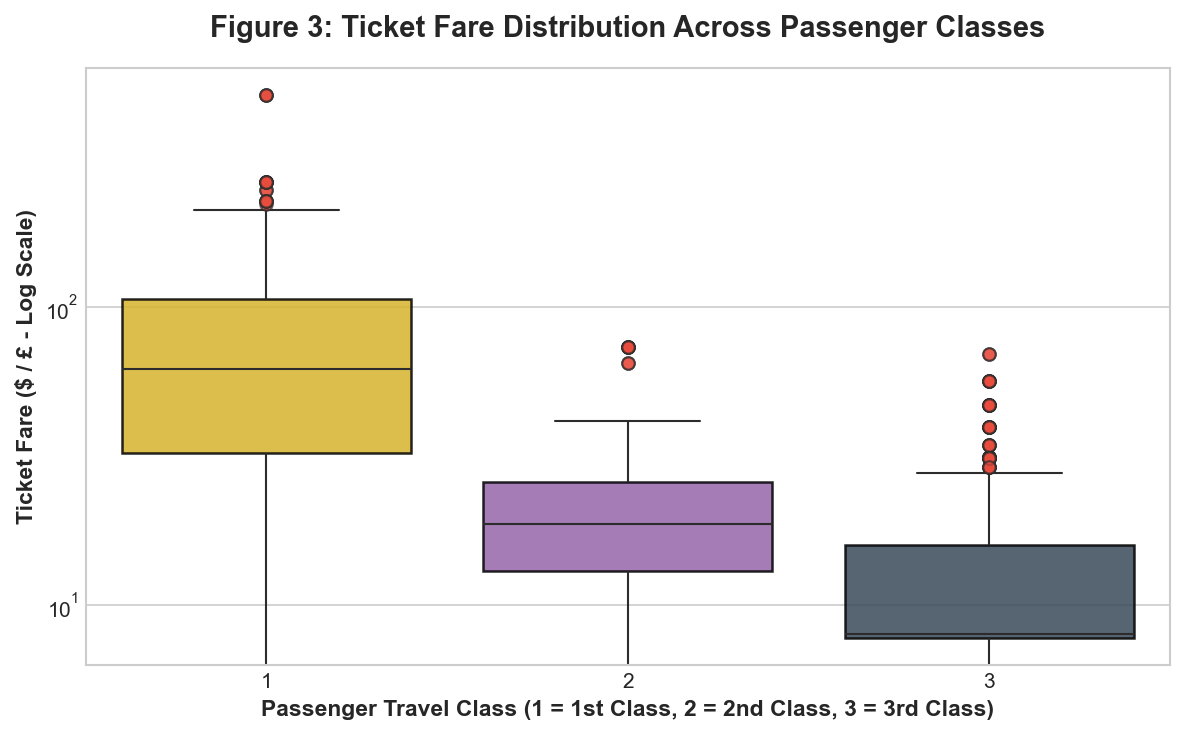

In [24]:
if 'df_clean' not in globals():
    import pandas as pd
    df_clean = pd.read_csv('titanic_cleaned.csv')
if 'plt' not in globals():
    import matplotlib.pyplot as plt
    import seaborn as sns

# 3. Box Plot: Ticket Fare Distribution Across Travel Classes
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df_clean,
    x='Passenger_Class',
    y='Fare',
    hue='Passenger_Class',
    palette=['#f1c40f', '#9b59b6', '#34495e'],
    legend=False,
    boxprops=dict(alpha=0.85, edgecolor='black', linewidth=1.2),
    flierprops=dict(marker='o', markerfacecolor='#e74c3c', markersize=6, alpha=0.7)
)

plt.title('Figure 3: Ticket Fare Distribution Across Passenger Classes', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Passenger Travel Class (1 = 1st Class, 2 = 2nd Class, 3 = 3rd Class)', fontsize=11, fontweight='bold')
plt.ylabel('Ticket Fare ($ / £ - Log Scale)', fontsize=11, fontweight='bold')
plt.yscale('log')
plt.tight_layout()
plt.show()


**Explanation and Analytical Observation:**
* **What the visualization shows:** This box plot displays the five-number summary (minimum, first quartile $Q_1$, median, third quartile $Q_3$, and maximum) of ticket fares across the three travel classes plotted on a logarithmic vertical scale to accommodate extreme values.
* **Observation:** First Class ticket fares have substantially higher medians and interquartile ranges (IQR) compared to Second and Third Class, along with prominent upper outliers reaching over £500. Third Class fares remain tightly compacted at low monetary values, confirming stark wealth disparities among passenger cohorts.


### 5.4 Visualization 4: Scatter Plot
**Chart Type:** Bivariate Numerical Relationship Plot


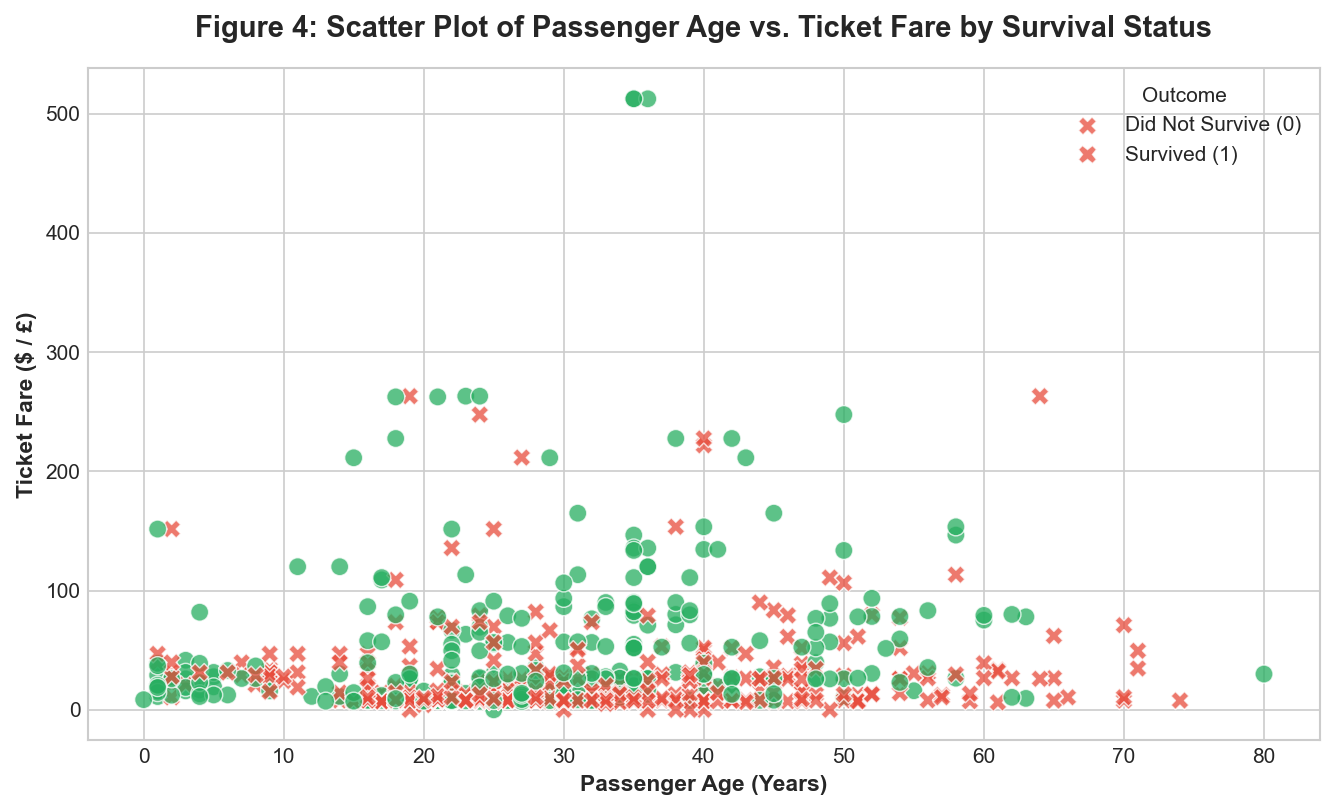

In [25]:
if 'df_clean' not in globals():
    import pandas as pd
    df_clean = pd.read_csv('titanic_cleaned.csv')
if 'plt' not in globals():
    import matplotlib.pyplot as plt
    import seaborn as sns

# 4. Scatter Plot: Passenger Age vs. Ticket Fare by Survival Status
plt.figure(figsize=(9, 5.5))
sns.scatterplot(
    data=df_clean,
    x='Age',
    y='Fare',
    hue='Survived',
    palette={0: '#e74c3c', 1: '#27ae60'},
    style='Survived',
    markers={0: 'X', 1: 'o'},
    s=75,
    alpha=0.75,
    edgecolor='w'
)

plt.title('Figure 4: Scatter Plot of Passenger Age vs. Ticket Fare by Survival Status', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Passenger Age (Years)', fontsize=11, fontweight='bold')
plt.ylabel('Ticket Fare ($ / £)', fontsize=11, fontweight='bold')
plt.legend(title='Outcome', labels=['Did Not Survive (0)', 'Survived (1)'], loc='upper right')
plt.tight_layout()
plt.show()


**Explanation and Analytical Observation:**
* **What the visualization shows:** This scatter plot plots individual passengers according to their continuous age on the horizontal axis and ticket fare paid on the vertical axis, with point colors and markers representing survival status (Green circle = Survived, Red X = Did Not Survive).
* **Observation:** High-fare passengers (those paying >£100) are clustered predominantly as green circles, indicating near-universal survival among top luxury ticket holders regardless of age. In contrast, the dense cluster of lower-fare passengers below £30 exhibits predominantly red markers across nearly all age brackets.


### 5.5 Visualization 5: Correlation Heatmap
**Chart Type:** Correlation Matrix Heatmap


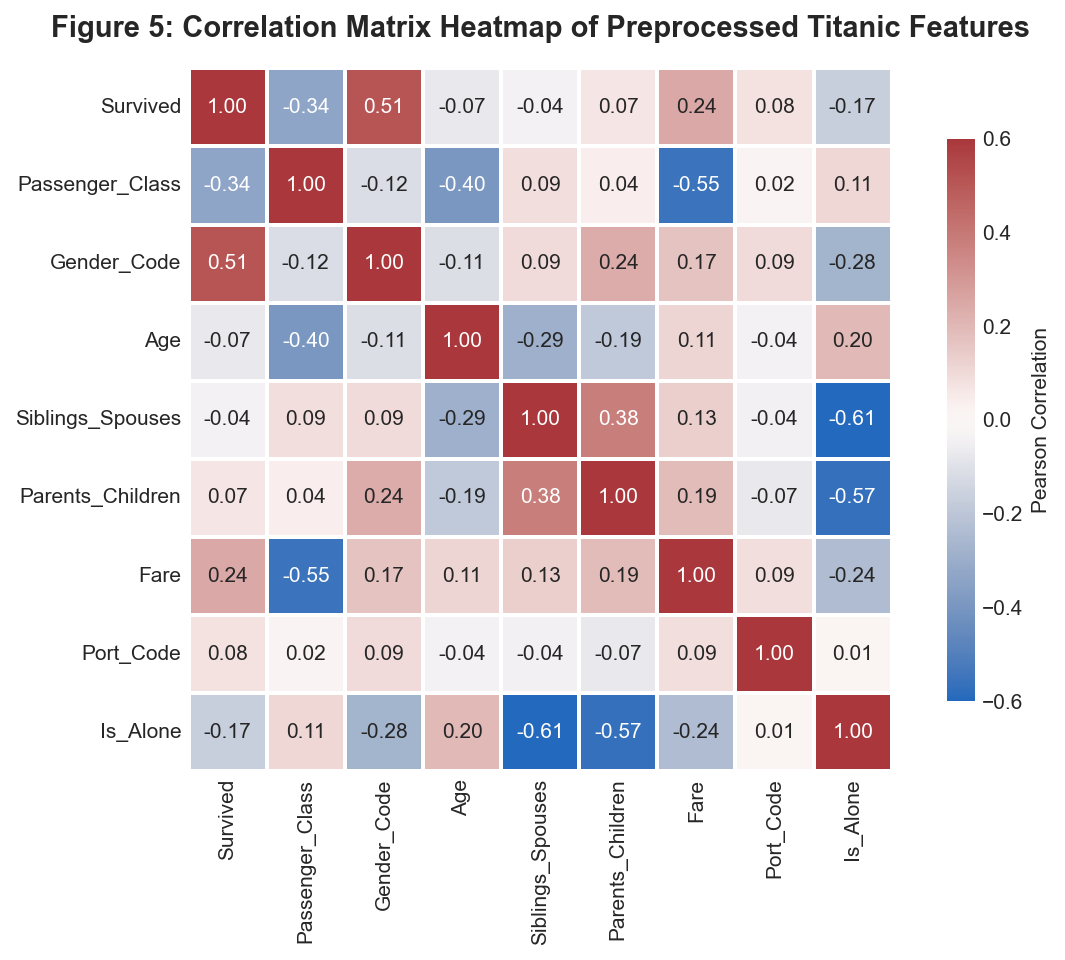

In [26]:
if 'df_clean' not in globals():
    import pandas as pd
    df_clean = pd.read_csv('titanic_cleaned.csv')
if 'plt' not in globals():
    import matplotlib.pyplot as plt
    import seaborn as sns
import numpy as np

# 5. Correlation Heatmap: Preprocessed Numerical Features
plt.figure(figsize=(8.5, 6.5))
corr_cols = ['Survived', 'Passenger_Class', 'Gender_Code', 'Age', 'Siblings_Spouses', 'Parents_Children', 'Fare', 'Port_Code', 'Is_Alone']
corr_matrix = df_clean[corr_cols].corr()

sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt='.2f', 
    cmap='vlag', 
    vmin=-0.6, 
    vmax=0.6, 
    center=0,
    square=True, 
    linewidths=1, 
    cbar_kws={'shrink': 0.8, 'label': 'Pearson Correlation'}
)

plt.title('Figure 5: Correlation Matrix Heatmap of Preprocessed Titanic Features', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


**Explanation and Analytical Observation:**
* **What the visualization shows:** This heatmap illustrates the pairwise Pearson linear correlation coefficients between all cleaned numerical and encoded features, using a diverging colormap where red signifies positive correlation, blue indicates negative correlation, and values are explicitly labeled.
* **Observation:** The strongest single positive correlation with survival is **`Gender_Code` ($r = +0.50$)**, confirming that being female was the single most decisive factor for survival. Additionally, `Passenger_Class` has a significant negative correlation with survival ($r = -0.33$) and fare ($r = -0.56$), substantiating that higher travel class (lower numerical rank 1) was strongly associated with higher survival probability and greater fares.


## Conclusion and Summary of Work
In this assignment, we accomplished the complete end-to-end data mining pipeline:
1. **Dataset Selection:** Validated that the Titanic dataset satisfies all dimensional, type, missing value, and duplicate constraints.
2. **Exploration:** Uncovered structural characteristics, statistics, null concentrations, and duplicate entries.
3. **Cleaning & Preprocessing:** Successfully imputed missing age with class-gender group medians, imputed categorical ports with mode, eliminated 6 redundant/sparse columns, removed duplicate rows, applied standardized column renaming, and encoded categorical variables numerically.
4. **Data Selection & Manipulation:** Demonstrated `loc[]` vs `iloc[]`, highlighted the key distinction with numerical index labels, filtered records with complex boolean conditions, sorted by numerical attributes, and aggregated insights via `groupby()`.
5. **Data Visualization:** Built five distinct chart types (Bar, Histogram with KDE, Box Plot, Scatter Plot, and Heatmap) adhering strictly to academic data mining visualization principles.
